# Tres modelos de PD: logit, supervivencia y transiciones
## Resumen
El benchmark usa 2.200 contratos sintéticos y reserva 865 para evaluación posterior en el tiempo. La tasa observada OOT fue 9,60%; las medias estimadas fueron 10,03% (logit), 9,92% (supervivencia) y 15,12% (transiciones). No selecciona un ganador para cartera real. La identidad de supervivencia, la extrapolación de logit y la pérdida de información al discretizar ratings se estudian por separado.

## Contexto y métodos
Logit estima $p_{12}$ y lo convierte a hazard mensual constante: $h=1-(1-p_{12})^{1/12}$. Supervivencia estima directamente $h_m=\sigma(\beta X+\gamma M_m+\alpha\log(1+edad_m))$. Markov proyecta distribuciones de rating con default absorbente; la nueva masa de default es el flujo desde estados vivos, no el stock acumulado en default.

### Supuestos y procedencia
Datos de `src/multimodel/data.py`, semilla 20261018. El mecanismo verdadero de defaults es un hazard logístico; el panel de ratings es una simulación distinta y deliberadamente imperfecta. El diseño favorece modelos próximos al generador. Los resultados verifican implementación, no superioridad general. Referencia metodológica: [Botha y Verster, 2025](https://arxiv.org/abs/2507.15441).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.multimodel import *
from src.multimodel.experiment import fit_experiment
from src.multimodel.validation import binary_metrics, bootstrap_mean_interval
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
COLORS = ["#245B78", "#BE672F", "#398168"]
ex = fit_experiment()


## Datos y separación temporal
Entrenamiento: originaciones 0–29, resultados hasta mes 65. OOT: originaciones 66–83; se excluye el intervalo intermedio. Las etiquetas se consideran maduras retrospectivamente. No hay cambios de régimen en este generador.

In [2]:
train = ex["cohort"][ex["cohort"].loan_id.isin(ex["train_ids"])]
print("Train:", len(train), "OOT:", len(ex["oot"]))
assert train.origination_month.max()+36 < ex["oot"].origination_month.min()
display(ex["pd_metrics"].round(5))

Train: 1335 OOT: 865


,model,accounts,defaults,observed_rate,predicted_rate,brier,log_loss,auc
0,pd_logit_12m,865,83,0.09595,0.10026,0.08059,0.28299,0.73885
1,pd_monthly_survival,865,83,0.09595,0.09924,0.08052,0.28407,0.73663
2,pd_rating_transitions,865,83,0.09595,0.15117,0.08617,0.30594,0.71453


## Resultados: discriminación y calibración
Brier y log-loss penalizan probabilidades erradas; AUC mide ordenamiento, no calibración. La tasa observada tiene el mismo denominador de contratos para los tres modelos.

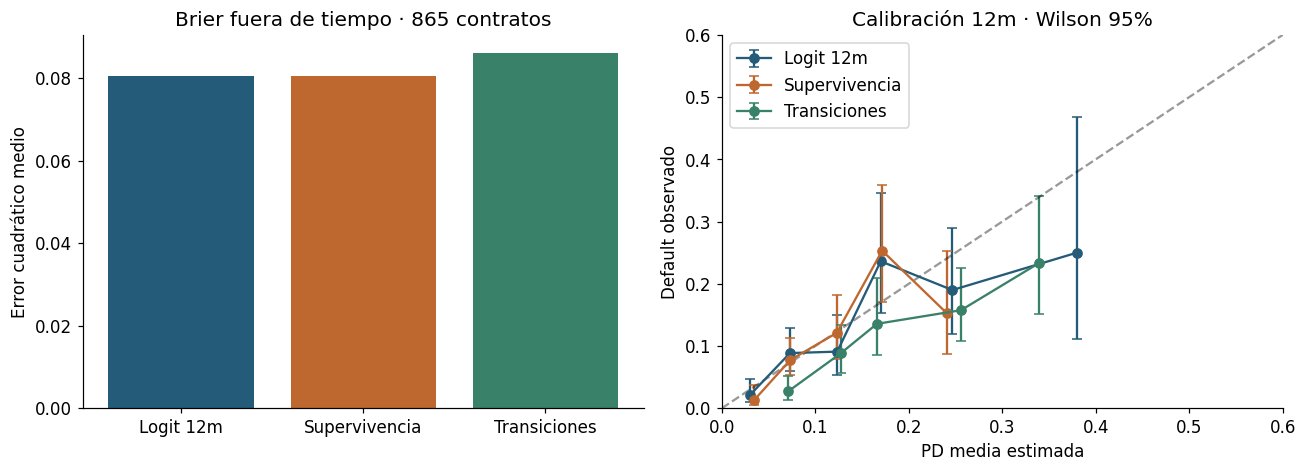

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
labels = ["Logit 12m", "Supervivencia", "Transiciones"]
axes[0].bar(labels, ex["pd_metrics"].brier, color=COLORS)
axes[0].set(title="Brier fuera de tiempo · 865 contratos", ylabel="Error cuadrático medio")
for model, color, label in zip(ex["pd_models"], COLORS, labels):
    p = ex["predictions"][model.model_id]
    f = pd.DataFrame({"p": p, "y": ex["oot"].default_12m.to_numpy()})
    f["bin"] = pd.cut(f.p, [0,.05,.1,.15,.2,.3,.5,1], include_lowest=True)
    g = f.groupby("bin", observed=True).agg(predicted=("p","mean"), observed=("y","mean"), n=("y","size"))
    g = g.loc[g.n >= 20]
    z = 1.96
    center = (g.observed+z*z/(2*g.n))/(1+z*z/g.n)
    half = z*np.sqrt(g.observed*(1-g.observed)/g.n+z*z/(4*g.n*g.n))/(1+z*z/g.n)
    axes[1].errorbar(g.predicted, g.observed, yerr=[g.observed-(center-half), (center+half)-g.observed], fmt="o-", capsize=3, color=color, label=label)
axes[1].plot([0,.6],[0,.6],"k--",alpha=.4)
axes[1].set(xlabel="PD media estimada", ylabel="Default observado", title="Calibración 12m · Wilson 95%", xlim=(0,.6), ylim=(0,.6))
axes[1].legend(); fig.tight_layout(); plt.show()

Se muestran únicamente bins con al menos 20 contratos; las barras son intervalos binomiales Wilson al 95% para la tasa observada, no intervalos de predicción de PD. No se concluye diferencia entre modelos por solapamiento visual. Evaluamos además diferencias de Brier pareadas con remuestreo por contrato, manteniendo ajustes fijos.

In [4]:
y = ex["oot"].default_12m.to_numpy()
base = ex["predictions"][ex["pd_models"][0].model_id]
for m in ex["pd_models"][1:]:
    p = ex["predictions"][m.model_id]
    delta = (p-y)**2-(base-y)**2
    print(m.model_id, "delta Brier:", round(delta.mean(),6), "IC bootstrap 95%:", bootstrap_mean_interval(delta))

pd_monthly_survival delta Brier: -7.1e-05 IC bootstrap 95%: (np.float64(-0.0008878696973974269), np.float64(0.000849797452566063))
pd_rating_transitions delta Brier: 0.005587 IC bootstrap 95%: (np.float64(0.0024922896797602355), np.float64(0.008528506515881131))


### Curvas de vida y escenario
Comparamos el mismo contrato vivo y un factor macro estandarizado constante. Este factor no representa puntos de desempleo ni PIB. La PD de vida es $\sum_m q_m$, con $q_m=S_{m-1}h_m$.

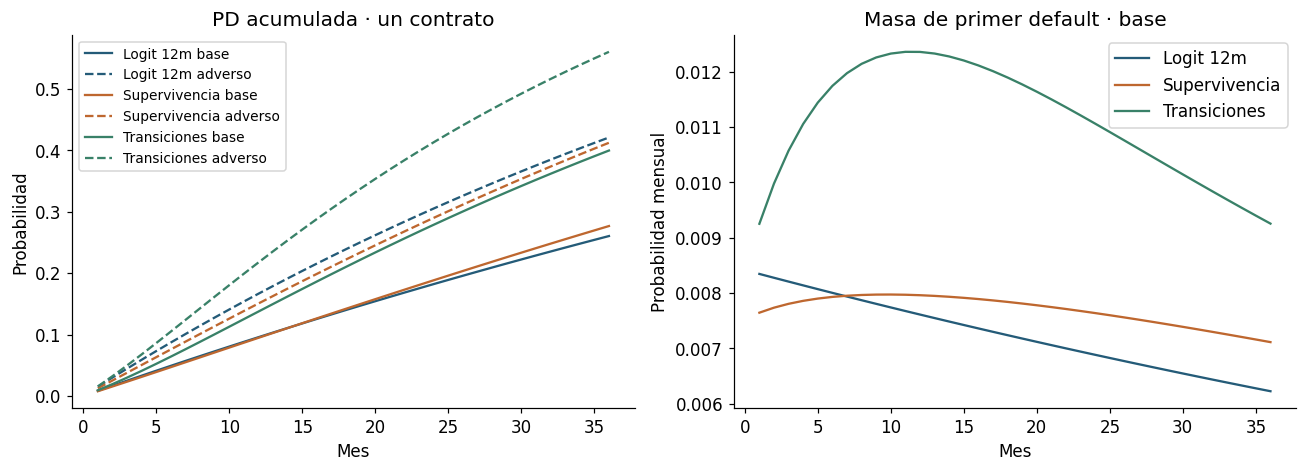

In [5]:
loan = ex["loans"].query("stage != 3").iloc[[0]]
fig, axes = plt.subplots(1,2,figsize=(12,4.4))
for model,color,label in zip(ex["pd_models"],COLORS,labels):
    for shock,style in [(0.,"-"),(1.5,"--")]:
        mass=model.predict_curve(loan,np.full(36,shock))[0]
        assert (mass>=0).all() and mass.sum()<=1+1e-12
        axes[0].plot(np.arange(1,37),mass.cumsum(),style,color=color,label=label+(" base" if shock==0 else " adverso"))
    axes[1].plot(np.arange(1,37),model.predict_curve(loan,np.zeros(36))[0],color=color,label=label)
axes[0].set(title="PD acumulada · un contrato",xlabel="Mes",ylabel="Probabilidad")
axes[1].set(title="Masa de primer default · base",xlabel="Mes",ylabel="Probabilidad mensual")
axes[0].legend(fontsize=9);axes[1].legend();fig.tight_layout();plt.show()

### Prueba analítica de extrapolación

In [6]:
model=ex["pd_models"][0]
annual=model.estimator.predict_proba(np.column_stack([loan.score,loan.segment,[0.]]))[:,1]
mass=model.predict_curve(loan,np.zeros(36))
np.testing.assert_allclose(mass[:,:12].sum(axis=1),annual)
np.testing.assert_allclose(mass.sum(axis=1),1-(1-annual)**3)
print("Logit: identidad de conversión 12m y extrapolación a 36m verificadas.")

Logit: identidad de conversión 12m y extrapolación a 36m verificadas.


## Conclusiones y límites
Las métricas anteriores comparan probabilidades para el mismo evento a 12 meses. La calibración de vida a 36 meses exige otro backtest; no se infiere del de 12 meses. La supervivencia admite censura administrativa; aquí no hay prepago en el panel de defaults. Markov pierde covariables continuas y su sensibilidad macro es un supuesto suministrado. Próximos pasos: datos históricos, vintages macro, validación por segmento y evaluación de censura informativa.